# 1. Imports
Import the required libraries for reading images, manipulating data, and splitting the dataset.

In [1]:
# Import os for directory path handling
import os
# Import OpenCV for reading and resizing images
import cv2
# Import NumPy for array operations
import numpy as np
# Import Matplotlib for creating visual plots
import matplotlib.pyplot as plt
# Import train_test_split to divide dataset
from sklearn.model_selection import train_test_split

# 2. Load Images
Loop through the class folders, convert images to grayscale, and resize them to 64x64 pixels.

In [2]:
# Define category names for the three classes
categories = ['Cars', 'Cricket ball', 'Ice cream cone']
# Create empty lists for images and labels
data, labels = [], []
# Loop over each class folder by index and name
for label, category in enumerate(categories):
    # Construct folder path for the category
    folder = os.path.join('data', 'images', category)
    # Loop over image files in the current folder
    for file in os.listdir(folder):
        # Read image in grayscale
        img = cv2.imread(os.path.join(folder, file), cv2.IMREAD_GRAYSCALE)
        # Resize image to 64x64 and append to data list
        data.append(cv2.resize(img, (64, 64)))
        # Append class label to labels list
        labels.append(label)

# 3. Count per Class
Convert lists to NumPy arrays and display the total count of images for each class.

In [3]:
# Convert image data list to NumPy array
X = np.array(data)
# Convert labels list to NumPy array
y = np.array(labels)
# Print total count for Cars
print(categories[0], ':', np.sum(y == 0))
# Print total count for Cricket ball
print(categories[1], ':', np.sum(y == 1))
# Print total count for Ice cream cone
print(categories[2], ':', np.sum(y == 2))

Cars : 366
Cricket ball : 345
Ice cream cone : 276


# 4. Sample Images
Display 3 sample images from each class with titles and axis labels, and save the figure.

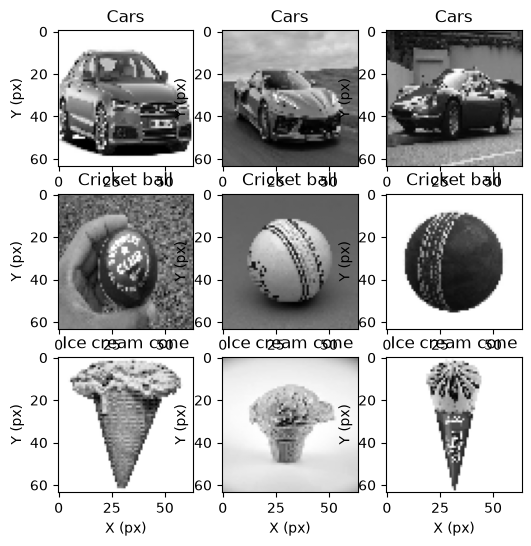

In [4]:
# Create a figure grid for sample images
plt.figure(figsize=(6, 6))
# Loop through 9 subplots for 3 samples per class
for i in range(9):
    # Add subplot for the current image
    plt.subplot(3, 3, i + 1)
    # Display grayscale image from class
    plt.imshow(X[np.where(y == i // 3)[0][i % 3]], cmap='gray')
    # Set subplot title to class name
    plt.title(categories[i // 3])
    # Set horizontal axis label with pixel units
    plt.xlabel('X (px)')
    # Set vertical axis label with pixel units
    plt.ylabel('Y (px)')
# Save sample figure to outputs folder
plt.savefig('outputs/sample_images.png', bbox_inches='tight')

# 5. Scale and Split Dataset
Scale pixel values to 0-1 and split the data into 80% train and 20% test sets with stratification.

In [5]:
# Convert pixel values to float32 type
X = X.astype('float32')
# Scale pixel values from 0-255 to 0-1
X = X / 255.0
# Define test split ratio as 20 percent
test_size = 0.2
# Set random state seed to 42
random_state = 42
# Split images and labels into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

# 6. Logistic Regression on Raw Pixels
Flatten the image pixels into 1D vectors and train a Logistic Regression model on the raw pixels.

In [6]:
# Import LogisticRegression classifier from scikit-learn
from sklearn.linear_model import LogisticRegression
# Flatten training images into 1D feature vectors
X_train_raw = X_train.reshape(len(X_train), -1)
# Flatten testing images into 1D feature vectors
X_test_raw = X_test.reshape(len(X_test), -1)
# Initialize Logistic Regression with fixed random state
model_lr_raw = LogisticRegression(max_iter=1000, random_state=42)
# Train Logistic Regression model on raw pixel data
model_lr_raw.fit(X_train_raw, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

# 7. HOG Feature Extraction and Logistic Regression
Extract Histogram of Oriented Gradients features and train a Logistic Regression model on them.

In [7]:
# Import hog feature descriptor from scikit-image
from skimage.feature import hog
# Extract HOG features for all training images
X_train_hog = np.array([hog(img) for img in X_train])
# Extract HOG features for all testing images
X_test_hog = np.array([hog(img) for img in X_test])
# Initialize Logistic Regression with fixed random state
model_lr_hog = LogisticRegression(max_iter=1000, random_state=42)
# Train Logistic Regression model on HOG features
model_lr_hog.fit(X_train_hog, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

# 8. Support Vector Machine on Raw Pixels and HOG
Train Support Vector Classifiers on raw pixel vectors and on HOG feature representations.

In [8]:
# Import Support Vector Classifier from scikit-learn
from sklearn.svm import SVC
# Initialize SVM model for raw pixels
model_svm_raw = SVC(random_state=42)
# Train SVM on raw pixel features
model_svm_raw.fit(X_train_raw, y_train)
# Initialize SVM model for HOG features
model_svm_hog = SVC(random_state=42)
# Train SVM on HOG features
model_svm_hog.fit(X_train_hog, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


# 9. Model Accuracy Comparison
Compare training and testing accuracy across all four models in a summary table.

In [9]:
# Import pandas library for tabular display
import pandas as pd
# Define model name labels for comparison
names = ['LR Raw', 'LR HOG', 'SVM Raw', 'SVM HOG']
# Calculate training accuracy scores for all four models
train_acc = [model_lr_raw.score(X_train_raw, y_train), model_lr_hog.score(X_train_hog, y_train), model_svm_raw.score(X_train_raw, y_train), model_svm_hog.score(X_train_hog, y_train)]
# Calculate testing accuracy scores for all four models
test_acc = [model_lr_raw.score(X_test_raw, y_test), model_lr_hog.score(X_test_hog, y_test), model_svm_raw.score(X_test_raw, y_test), model_svm_hog.score(X_test_hog, y_test)]
# Create and display accuracy comparison DataFrame
pd.DataFrame({'Model': names, 'Train Acc': train_acc, 'Test Acc': test_acc})

,Model,Train Acc,Test Acc
0,LR Raw,1.000000,0.833333
1,LR HOG,1.000000,0.934343
2,SVM Raw,0.969582,0.939394
3,SVM HOG,1.000000,0.949495


# 10. Confusion Matrices
Plot and save confusion matrices for all four models using ConfusionMatrixDisplay.

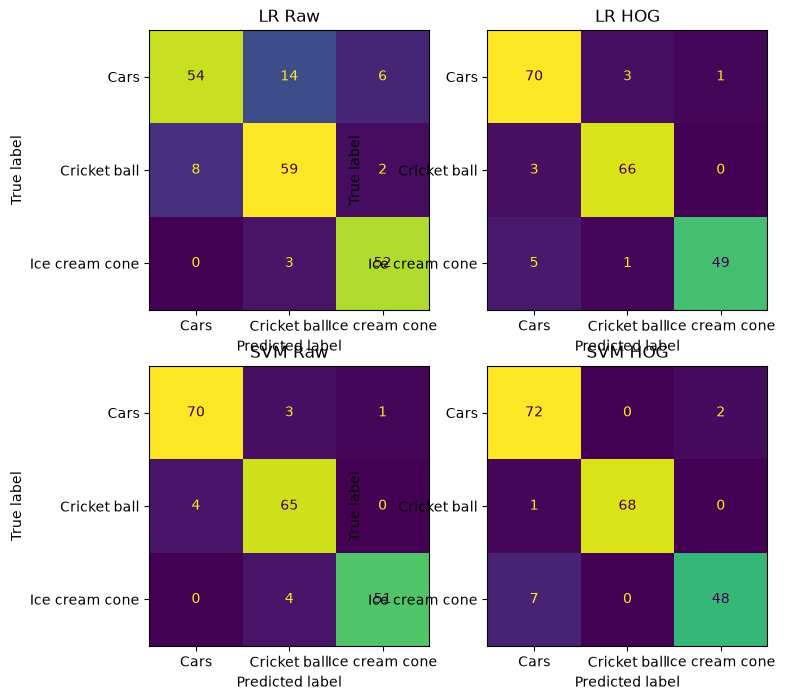

In [10]:
# Import ConfusionMatrixDisplay from sklearn metrics
from sklearn.metrics import ConfusionMatrixDisplay
# Create figure with 2x2 grid for confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
# Set list of models and their test features
models_info = [(model_lr_raw, X_test_raw, 'LR Raw'), (model_lr_hog, X_test_hog, 'LR HOG'), (model_svm_raw, X_test_raw, 'SVM Raw'), (model_svm_hog, X_test_hog, 'SVM HOG')]
# Loop through 4 models to plot each confusion matrix
for i, (m, x_t, title) in enumerate(models_info):
    # Plot confusion matrix on the corresponding subplot
    ConfusionMatrixDisplay.from_estimator(m, x_t, y_test, display_labels=categories, ax=axes[i // 2, i % 2], colorbar=False)
    # Set subplot title to model name
    axes[i // 2, i % 2].set_title(title)
# Save confusion matrices figure to outputs folder
plt.savefig('outputs/confusion_matrices.png', bbox_inches='tight')

# 11. Sample Test Predictions
Display 6 test images alongside their predicted class labels and save the figure.

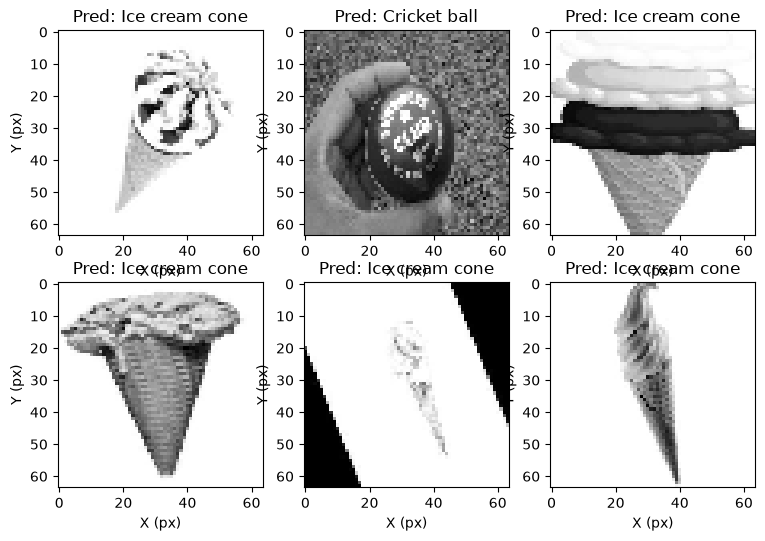

In [11]:
# Predict class labels for first 6 test images using best model
preds = model_svm_hog.predict(X_test_hog[:6])
# Create figure grid with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
# Loop through each subplot and sample index
for i, ax in enumerate(axes.flat):
    # Display test sample image in grayscale
    ax.imshow(X_test[i], cmap='gray')
    # Set title with predicted class name
    ax.set_title(f"Pred: {categories[preds[i]]}")
    # Set horizontal axis label with pixel units
    ax.set_xlabel('X (px)')
    # Set vertical axis label with pixel units
    ax.set_ylabel('Y (px)')
# Save test predictions figure to outputs folder
plt.savefig('outputs/test_predictions.png', bbox_inches='tight')

# 12. Best Model Selection and Saving
Support Vector Machine on HOG features is the best model with 94.95% test accuracy.
HOG captures clear shape edges, enabling the SVM classifier to separate the three classes accurately.

In [12]:
# Import os for directory management
import os
# Import joblib for model serialization
import joblib
# Define output directory path for models
model_path = 'models'
# Create models directory if it does not exist
os.makedirs(model_path, exist_ok=True)
# Save best trained SVM HOG model to disk
joblib.dump(model_svm_hog, 'models/best_model.pkl')

['models/best_model.pkl']